In [1]:
import PDE_fittingTools as SS
from scipy import optimize as opt

import iminuit
from iminuit import Minuit

import numpy as np
import matplotlib.pyplot as plt

In [2]:
## Testing/example
# Step 0: define your function to fit
def testFunctionA(x, a=0, b=0, c=10, x_systematic = 0):
    # print("a", a, "b", b, "c", c)
    return a*(x-x_systematic)**2 + b*(x-x_systematic) + c

print("arguments that must be included in dicts below:", SS.GetNames(testFunctionA))

arguments that must be included in dicts below: ['x', 'a', 'b', 'c', 'x_systematic']


---
## One dimension fitting example (no nuisance parameters)
Here you have a 1:1 mapping between all your floating variables. There is no variables that float for each dataset, or that float for some data and not for others

* This code below gets wrapped into another function to do higher dimensionality fitting (Nuisance parameters)

In [3]:
### -- How to use the code in PDE_fittingTools --- ###

# step 1: define the variables you will fix and float
# fixed variables (don't change)
fixedDict = {"b":0, "a":1.0}
xShift_system = 3.

# float variables (do fit)
floatDict = {"c":5} # guesses
floatBounds = {"c":(0, 10)}

## Step 2: layout your data set (probably better to do first actually)
# this is the layout of a single dataset. An array of dictionairies for each 1d dataset
# x data must be named same thing as the function
xData = np.arange(-2, 4, 0.1)
yData = 0.5+testFunctionA(x=xData, **fixedDict, **floatDict) + np.random.normal(scale=0.1, size=len(xData))
xData2 = xData + xShift_system
yData2 = 0.5+testFunctionA(x=xData2, x_systematic=xShift_system, **fixedDict, **floatDict) + np.random.normal(scale=0.1, size=len(xData))

# y data must be names 'yVals', if errors included must be called 'yErrs'
dataExample = [{"x":xData, "yVals":yData, "x_systematic":0, "yErrs":np.ones_like(yData)}]
dataExample = [
    {"x":xData, "yVals":yData, "x_systematic":0},
    {"x":xData2, "yVals":yData2, "x_systematic":xShift_system}
    ]
# this will also work (without errors)
# if you have parameters that change for each dataset. you include them in the dataset dictionary! how cool is that?
               

# dataKeys + fixedDict + floatDict should have all the things that the fit function accepts, plus one extra for the input y data

## Step 3. check conditions/logic of your inputs
# (there is a lot of annoying logic behind the scenes here)
# single call:
SS.CheckAllConditions_forResiduals(func=testFunctionA, dataObj=dataExample, dFixed=fixedDict, dFloat=floatDict, yNames = ("yVals", "yErrs"), verbose = True);

    # broken down, above does the following:
    # 3.1 check that the keys/dimensions of EACH one dimensional dataset are correct
    # SS.CheckDataKeys(dataObj=dataExample, func=testFunctionA, verbose=True);

    # 3.2 check that the fixed, float, and data dictionaries are complete wrt the function
    # yNames by default is ['yVals', 'yErrs']
    # SS.CheckInputKeySets_completeness(func=testFunctionA, dataObj=dataExample, dFloat=floatDict,  dFixed=fixedDict, yNames = ("yVals", "yErrs"));

    # 3.3 check that the fixed, float, and data dictionaries are consistent wrt the residual logic (also does the sorting)
    # x0, x0Names = SS.BuildX0(floatDict, testFunctionA)
    # SS.CheckInputs_forResiduals(x0=x0, fixedArgs_dict=fixedDict, dataObj=dataExample, functionToFit=testFunctionA, yNames=("yVals", "yErrs"), verbose=True):


------- CheckAllConditions_forResiduals(function=testFunctionA) -------
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed
-- CheckInputKeySets_completeness(func=testFunctionA) --
	Success: one extra key in data array: {'yVals'} 	(no uncertainties included)
	Float/fixed dicts and data are complete, all keys are accounted for.
-- CheckInputs_forResiduals(function=testFunctionA) --
	---------------- data block 0 --------------------
		float dict (from x0): {'c': 5}
		fixed dict: {'b': 0, 'a': 1.0}
		dataDict for function, (keys): {'x': [-2.0, -1.9, -1.7999999999999998, '...'], 'x_systematic': 0}
		dataDict for data (y): {'yVals': [9.625157129294053, 8.990663420469753, 8.791336146640488, '...']}
	---------------- data block 1 --------------------
		float dict (from x0): {'c': 5}
		fixed dict: {'b': 0, 'a': 1.0}
		dataDict for function, (keys): {'x': [1.0, 1.1, 1.2000000000000002, '...'], 'x_systematic': 3.0}
		dataDict for data (y): {'yVals': [9.435827318380712, 9.0766

In [4]:
## step 4: sort the float arguments to match function order.
x0, x0Names = SS.BuildX0(floatDict, testFunctionA)
x0Bounds = SS.BuildX0_bounds(floatBounds, testFunctionA)

print("input float pars array:")
print("names", x0Names)
print("vals", x0)
print("bounds", x0Bounds)

input float pars array:
names ['c']
vals [5]
bounds [(0, 10)]


In [5]:
def print_dict(d):
    for key, value in d.items():
        if isinstance(value, (list, tuple, set)) and len(value) > 3:
            value = list(value)[:3] + ['...']
        print(f'{key}: {value}')

# Test with a dictionary
d = {'key1': [1, 2, 3, 4, 5], 'key2': 'value2', 'key3': (6, 7, 8, 9, 10)}
print_dict(d)

key1: [1, 2, 3, '...']
key2: value2
key3: [6, 7, 8, '...']


In [6]:
## Step 4: test your function, and residual function
testFunctionA(x=xData, **fixedDict, **floatDict)
SS.GenericResiduals(x0=x0, fixedArgs_dict=fixedDict, dataObj=dataExample, functionToFit=testFunctionA, verbose=True)

------- GenericResiduals(function=testFunctionA) -------
	all input parameters (except data):  ['a', 'b', 'c']
	floating args:  ['c']
	---------------- data block 0 --------------------
		float dict (from x0): {'c': 5}
		fixed dict: {'b': 0, 'a': 1.0}
		dataDict for function, (keys): {'x': [-2.0, -1.9, -1.7999999999999998, '...'], 'x_systematic': 0}
		dataDict for data (y): {'yVals': [9.625157129294053, 8.990663420469753, 8.791336146640488, '...']}
	---------------- data block 1 --------------------
		float dict (from x0): {'c': 5}
		fixed dict: {'b': 0, 'a': 1.0}
		dataDict for function, (keys): {'x': [1.0, 1.1, 1.2000000000000002, '...'], 'x_systematic': 3.0}
		dataDict for data (y): {'yVals': [9.435827318380712, 9.07664883860507, 8.591686604617891, '...']}
	----------------


33.02392447028278

In [7]:
## Step 5: run the fit, the order of args passed to minimize IS IMPORTANT
# args = (fixedDict, dataObj, testFunctionA, yNames(optional), verbose(optional)
result = iminuit.minimize(SS.GenericResiduals, x0=x0, bounds = x0Bounds, args=(fixedDict, dataExample, testFunctionA), method='migrad')
print(result)

# organize your errors and results
resErrors = SS.GetErrorFromInvHess(inv_hess=result.hess_inv)
resDict = {x0Names[i]: round(result.x[i], 3) for i in range(len(x0Names))}
resErrorsDict = {x0Names[i]: round(resErrors[i], 3) for i in range(len(x0Names))}

print("result dict:", resDict)
print("result errors:", resErrorsDict)


  message: Optimization terminated successfully.
  success: True
      fun: 1.461180055564828
        x: [ 5.513e+00]
 hess_inv: ┌────┬─────────┐
           │    │      x0 │
           ├────┼─────────┤
           │ x0 │ 0.00417 │
           └────┴─────────┘
     nfev: 16
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 1.461                      │              Nfcn = 16               │
           │ EDM = 7.45e-09 (Goal: 0.0001)    │                                      │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │          Valid Minimum           │   Below EDM threshold (goal x 10)    │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │      N

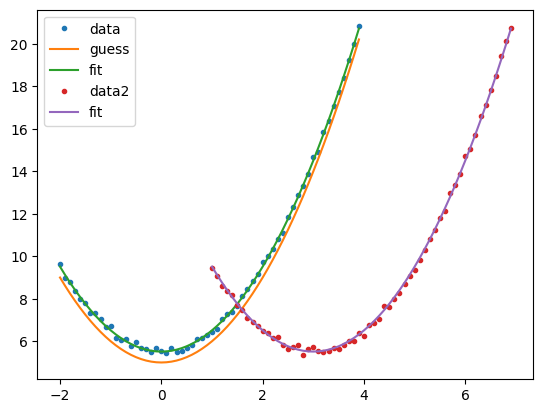

In [8]:

## Step 6: plot the results!
plt.plot(xData, yData, label = "data", marker=".", linestyle="none")
plt.plot(xData, testFunctionA(x=xData, **fixedDict, **floatDict), label = "guess")
plt.plot(xData, testFunctionA(x=xData, **fixedDict, **resDict), label = "fit")

plt.plot(xData2, yData2, label = "data2", marker=".", linestyle="none")
plt.plot(xData2, testFunctionA(x=xData2, x_systematic=xShift_system, **fixedDict, **resDict), label = "fit")

plt.legend()
plt.show()

---
## Nested fitting

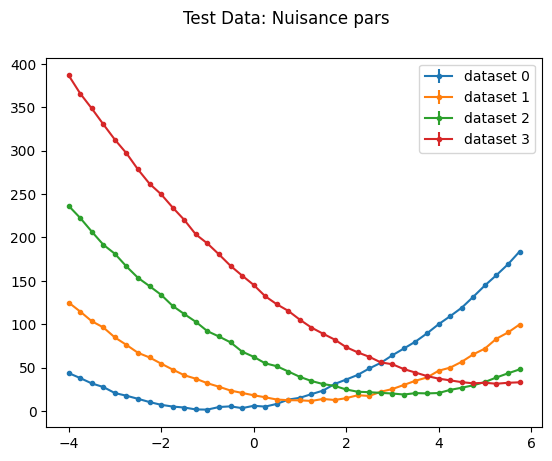

In [9]:
## First lets generate a more complex dataset.
import random

# we will have 4 quadratic datasets, each with a different offset, sharing a common slope and curvature
xData = np.arange(-4, 6, 0.25)
offsets = list(np.arange(2, 8, 2))
sigma = 1.0

mcSlope = 6.9
mcCurvature = 4.2

dataExample_nuis = []
for i in range(4):
    randomOffset = random.choice(offsets) + 10*i
    horizontalOffset = 2*i
    yData = 0.5+testFunctionA(x=xData, a=mcCurvature, b=mcSlope, c=randomOffset, x_systematic=horizontalOffset) + np.random.normal(scale=sigma, size=len(xData))
    oneD_dict = {"x":xData, "yVals":yData, "x_systematic":horizontalOffset}
    dataExample_nuis.append(oneD_dict)
    
# lets plot the data
for i in range(4):
    plt.errorbar(dataExample_nuis[i]["x"], dataExample_nuis[i]["yVals"], yerr=sigma, label = f"dataset {i}", marker=".")

plt.suptitle("Test Data: Nuisance pars")
plt.legend()
plt.show()

In [10]:
## Make complete dataset for nested fitting
fullData = []
temp_NuisanceDict = {"c":5}
temp_NuisanceDict_bounds = {"c":(-20, 10)}
temp_NuisanceDict_bounds["c"] = (None, None)

## this data will have the structure:
#list[  OneDimensionDict_Nuisance, OneDimensionDict_Nuisance, ...]

fullDataPackage = []
# build the complete nuisance parameter dataset
for oneD in dataExample_nuis:
    
    temp_NuisanceDict["c"] = min(oneD["yVals"]) # parameter guesses for each dataset
    # print("temp_NuisanceDict", temp_NuisanceDict)
    
    odFull = SS.OneNuisanceDataSet(oneDData=oneD, nuisanceFloat=temp_NuisanceDict, nuisanceBounds=temp_NuisanceDict_bounds)
    fullDataPackage.append(odFull)

print(SS.GetNames(testFunctionA))

['x', 'a', 'b', 'c', 'x_systematic']


In [11]:
globalFixed = {"b":mcSlope}
globalFloat = {"a":mcCurvature*0.8} # make guess a little wrong
globalBounds = {"a":(0, 10)}
x0, x0Names = SS.BuildX0(globalFloat, testFunctionA)
x0Bounds = SS.BuildX0_bounds(globalBounds, testFunctionA)

# this call just does the nested fitting
SS.GenericResiduals_Nuisance_1(globalFloat=x0, globalFixed=globalFixed, dataPackage=fullDataPackage, functionToFit=testFunctionA,
                            testing=False, verbose=True)

------------------- new dataset -------------------
  message: Optimization terminated successfully.
  success: True
      fun: 2201.9331330126624
        x: [ 1.238e+01]
 hess_inv: ┌────┬────────┐
           │    │     x0 │
           ├────┼────────┤
           │ x0 │ 0.0125 │
           └────┴────────┘
     nfev: 13
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 2202                       │              Nfcn = 13               │
           │ EDM = 3.02e-16 (Goal: 0.0001)    │                                      │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │          Valid Minimum           │   Below EDM threshold (goal x 10)    │
           ├──────────────────────────────────┼───────────

42174.13312796761

In [12]:
# doing the full (global) minimization
globalFitResult = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0, bounds = x0Bounds, args=(globalFixed, fullDataPackage, testFunctionA), method='migrad')

globalResultDict = SS.GetResDict(globalFitResult, x0Names)
globalResultErrors= SS.GetErrorFromInvHess(globalFitResult.hess_inv)

# if you want to print each final nested fit result:
for i, dc in enumerate(fullDataPackage):
    print("----------- nested fit", i, "-----------")
    print(f"nested fit {i}:", dc.minuitResult)
print("----------- global fit -----------")
print(globalFitResult)
print(globalResultDict)
print(globalResultErrors)

----------- nested fit 0 -----------
nested fit 0:   message: Optimization terminated successfully.
  success: True
      fun: 38.61393905903142
        x: [ 4.741e+00]
 hess_inv: ┌────┬────────┐
           │    │     x0 │
           ├────┼────────┤
           │ x0 │ 0.0125 │
           └────┴────────┘
     nfev: 13
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 38.61                      │              Nfcn = 13               │
           │ EDM = 8.25e-16 (Goal: 0.0001)    │                                      │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │          Valid Minimum           │   Below EDM threshold (goal x 10)    │
           ├──────────────────────────────────┼─────────────

nuisanceParameterDict {'c': 4.7408}
nuisanceParameterDict {'c': 14.6722}
nuisanceParameterDict {'c': 22.5322}
nuisanceParameterDict {'c': 34.7234}


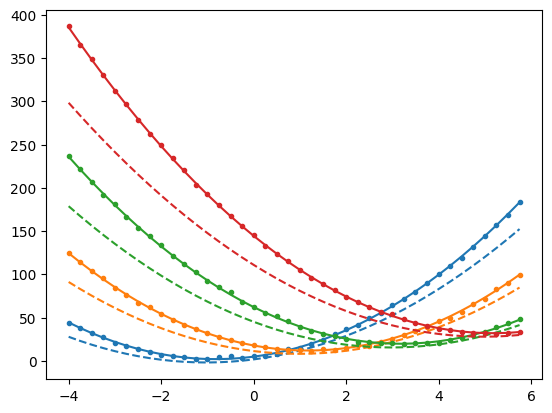

In [13]:
color_cycler = plt.rcParams['axes.prop_cycle'];color_cycler_iter = iter(color_cycler)
colors = [next(color_cycler_iter)['color'] for _ in range(10)]

funcAllArgs = SS.GetNames(testFunctionA)

for i, dc in enumerate(fullDataPackage): # datasets
    col = colors[i]
    data = dc.oneDData
    dataDict_forFunction = SS.NewDictFromKeysInList(dict1=data[0], keyList=funcAllArgs)
    nuisanceParameterDict = dc.resultDict # us this for the nuisance parameter arguments
    
    print("nuisanceParameterDict", nuisanceParameterDict)
    xGuessName = list(dataDict_forFunction.keys())[0]
    plt.plot(data[0][xGuessName], data[0]["yVals"], color=col, label = "data", marker=".", linestyle="none")
    
    plt.plot(data[0][xGuessName], testFunctionA(**dataDict_forFunction, **globalFloat, **globalFixed, **dc.mDict_nuisFloat),
             color=col, linestyle="--", label = "guess")
    
    plt.plot(data[0][xGuessName], testFunctionA(**dataDict_forFunction, **globalResultDict, **globalFixed, **dc.resultDict),
             color=col, label = "fit")
    